In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import LSTM, Dense
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)
tf.random.set_seed(42)

In [6]:
df = pd.read_excel('/Users/asyzyni/Desktop/Data Rapih Capstone/Data Capstone Fix BGt.xlsx')
target_col = 'Curah Hujan'

In [7]:
df

,Tanggal,Kelembapan Rata-Rata Udara Harian (%),Temperatur Rata-Rata Harian,Temperatur Maksimum Harian,Temperature Minimum Harian,Angin Rata-Rata Harian (Knot),Curah Hujan,Penyinaran Harian (%),Penguapan Harian (mm),Tekanan Udara Harian (mb)
0,2018-01-01,87.0,27.2,30.2,22.7,2.5,0,0.0,5.4,1008.0
1,2018-01-02,85.0,27.3,32.4,24.2,2.7,0,100.0,3.5,1008.5
2,2018-01-03,77.0,29.7,32.6,24.6,2.1,0,65.0,4.0,1009.3
3,2018-01-04,80.0,28.3,31.8,25.2,2.3,0,43.8,5.2,1009.1
4,2018-01-05,81.0,28.4,32.2,24.3,2.4,6,56.3,2.8,1009.8
...,...,...,...,...,...,...,...,...,...,...
1821,2022-12-27,85.0,27.5,30.0,25.4,3.1,32,0.0,7.7,1010.9
1822,2022-12-28,89.0,27.1,30.0,22.9,2.3,3.6,0.0,3.4,1010.8
1823,2022-12-29,91.0,26.0,28.7,24.8,7.1,21,0.0,6.4,1009.8
1824,2022-12-30,84.0,27.1,28.2,24.4,8.5,44.1,0.0,1.7,1010.8


In [9]:
df['Curah Hujan'] = df['Curah Hujan'].replace('TTU', 0.01)

/var/folders/v6/s7jbz6sn6qv9dh421jb6jbsm0000gn/T/ipykernel_34522/3604175414.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Curah Hujan'] = df['Curah Hujan'].replace('TTU', 0.01)


In [10]:
# Interpolasi & Normalisasi Z-score
df[target_col] = df[target_col].interpolate(method='linear', limit_direction='both')
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df[[target_col]].values)

In [11]:
# Fungsi Sliding Window (Pakai 5 urutan ke belakang)
def create_dataset(dataset, window_size):
    X, y = [], []
    for i in range(len(dataset) - window_size):
        X.append(dataset[i:(i + window_size), 0])
        y.append(dataset[i + window_size, 0])
    return np.array(X), np.array(y)

window_size = 5
X, y = create_dataset(data_scaled, window_size)

In [12]:
# Split 80% Training, 20% Testing secara absolut
train_size = int(len(X) * 0.80)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Siapkan format input untuk LSTM (3 Dimensi)
X_train_lstm = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test_lstm = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

# SVR hanya butuh 2 Dimensi (sudah sesuai format awal)
X_train_svr = X_train 
X_test_svr = X_test

# Fungsi Evaluasi Metrik

In [13]:
def calc_maape(y_true, y_pred):
    diff = np.abs((y_true - y_pred) / (y_true + 1e-8))
    return np.mean(np.arctan(diff))

def evaluate_model(model_name, y_true, y_pred):
    maape_val = calc_maape(y_true, y_pred)
    rmse_val = np.sqrt(mean_squared_error(y_true, y_pred))
    mae_val = mean_absolute_error(y_true, y_pred)
    return {'Model': model_name, 'MAAPE': maape_val, 'RMSE': rmse_val, 'MAE': mae_val}

# Training Model

SVR

In [14]:
svr_model = SVR(kernel='rbf', C=1.0, gamma='scale')
svr_model.fit(X_train_svr, y_train)
pred_svr_scaled = svr_model.predict(X_test_svr)

LSTM

In [15]:
lstm_model = Sequential()
lstm_model.add(LSTM(100, input_shape=(window_size, 1)))
lstm_model.add(Dense(1))
lstm_model.compile(optimizer='adam', loss='mse')
# Latih dengan epoch kecil dulu biar cepat, nanti bisa ditambah kalau butuh
lstm_model.fit(X_train_lstm, y_train, epochs=100, batch_size=32, verbose=0) 
pred_lstm_scaled = lstm_model.predict(X_test_lstm, verbose=0).flatten()

2026-05-07 09:14:47.019740: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2026-05-07 09:14:47.021543: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-05-07 09:14:47.022612: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-05-07 09:14:47.023013: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-07 09:14:47.023582: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
/opt/anaconda3/envs/streamlit_env/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Seque

Hibrida 

In [16]:
feature_extractor = Model(inputs=lstm_model.inputs, outputs=lstm_model.layers[0].output)

In [17]:
# Ekstrak fitur (Pola-pola tersembunyi dari data curah hujan)
X_train_features = feature_extractor.predict(X_train_lstm, verbose=0)
X_test_features = feature_extractor.predict(X_test_lstm, verbose=0)

# Masukkan fitur yang sudah pintar itu ke dalam SVR
hybrid_model = SVR(kernel='rbf', C=1.0, gamma='scale')
hybrid_model.fit(X_train_features, y_train)
pred_hybrid_scaled = hybrid_model.predict(X_test_features)

# Inverse Transform & Hitung Error

In [18]:
y_test_asli = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

pred_svr_asli = scaler.inverse_transform(pred_svr_scaled.reshape(-1, 1)).flatten()
pred_lstm_asli = scaler.inverse_transform(pred_lstm_scaled.reshape(-1, 1)).flatten()
pred_hybrid_asli = scaler.inverse_transform(pred_hybrid_scaled.reshape(-1, 1)).flatten()

results = []
results.append(evaluate_model('SVR', y_test_asli, pred_svr_asli))
results.append(evaluate_model('LSTM', y_test_asli, pred_lstm_asli))
results.append(evaluate_model('Hibrida LSTM-SVR', y_test_asli, pred_hybrid_asli))

In [19]:
df_results = pd.DataFrame(results)

# HAsil

           Model    MAAPE     RMSE      MAE
             SVR 1.291140 8.770577 3.854210
            LSTM 1.319994 9.430230 4.821251
Hibrida LSTM-SVR 1.301302 8.753719 3.914977


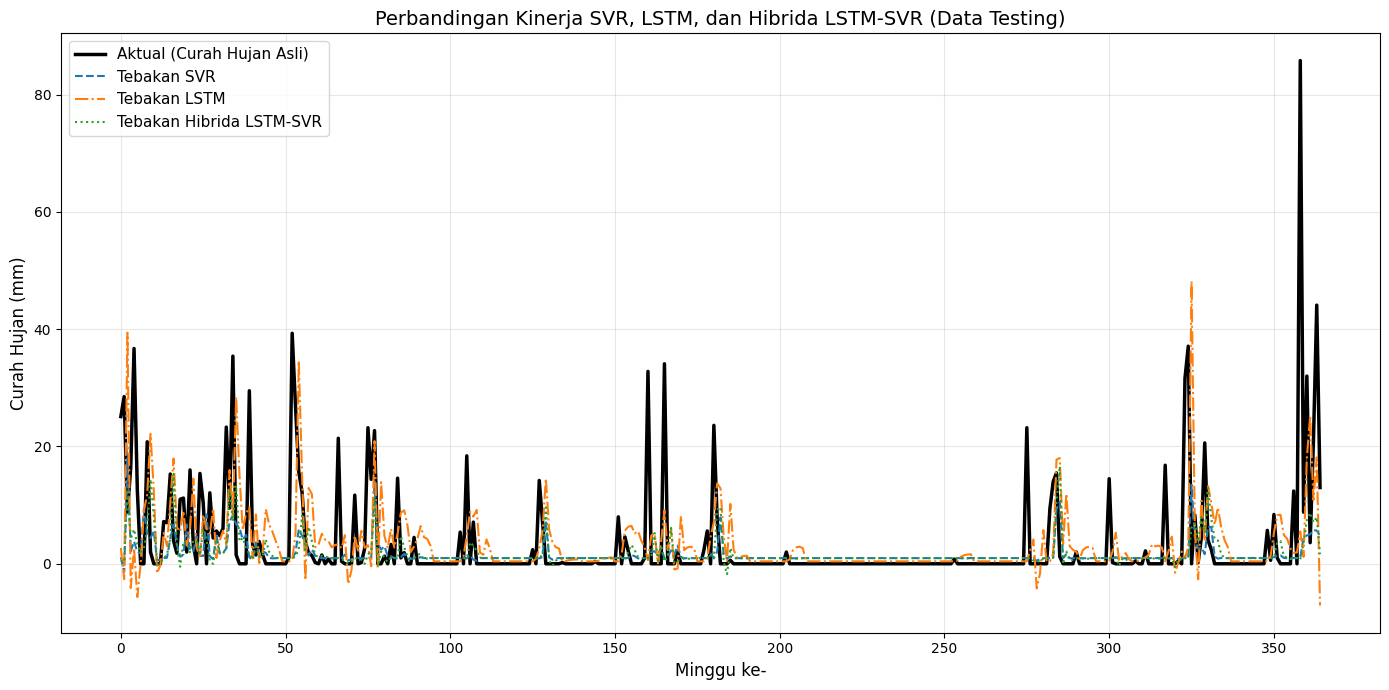

In [20]:
print(df_results.to_string(index=False))

plt.figure(figsize=(14, 7))
# Plot data asli dengan garis tebal hitam
plt.plot(y_test_asli, label='Aktual (Curah Hujan Asli)', color='black', linewidth=2.5)

# Plot prediksi masing-masing model
plt.plot(pred_svr_asli, label='Tebakan SVR', linestyle='--')
plt.plot(pred_lstm_asli, label='Tebakan LSTM', linestyle='-.')
plt.plot(pred_hybrid_asli, label='Tebakan Hibrida LSTM-SVR', linestyle=':')

plt.title('Perbandingan Kinerja SVR, LSTM, dan Hibrida LSTM-SVR (Data Testing)', fontsize=14)
plt.xlabel('Minggu ke-', fontsize=12)
plt.ylabel('Curah Hujan (mm)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()